In [2]:
import h5py

path = '/home/erikm/algonauts_2025.competitors/fmri/sub-01/func/sub-01_task-friends_space-MNI152NLin2009cAsym_atlas-Schaefer18_parcel-1000Par7Net_desc-s123456_bold.h5'

with h5py.File(path, 'r') as f:
    keys = list(f.keys())
    print('Number of recordings:', len(keys))
    print('First few:', keys[:6])
    print('Shape of first one:', f[keys[0]].shape)

Number of recordings: 292
First few: ['ses-001_task-s01e02a', 'ses-001_task-s01e02b', 'ses-001_task-s01e03a', 'ses-001_task-s01e03b', 'ses-002_task-s01e04a', 'ses-002_task-s01e04b']
Shape of first one: (482, 1000)


Each recording is half an episode, each snapshot taken every 1.49 seconds making 482 in the first recording. The brain is divided into 1000 areas each number being how active that area was at that snapshot

This makes up 146 episodes for participant 1, giving a data size of around 140 million or 140 thousand snapshots

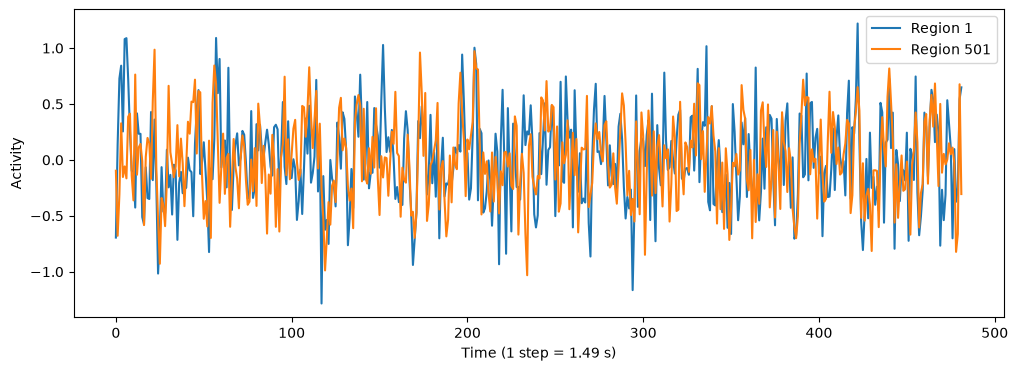

In [3]:
import matplotlib.pyplot as plt

with h5py.File(path, 'r') as f:
    data = f[keys[0]][:]

plt.figure(figsize=(12, 4))
plt.plot(data[:, 0], label='Region 1')
plt.plot(data[:, 500], label='Region 501')
plt.xlabel('Time (1 step = 1.49 s)')
plt.ylabel('Activity')
plt.legend()
plt.show()

Correlation between region 1 and 501: 0.35


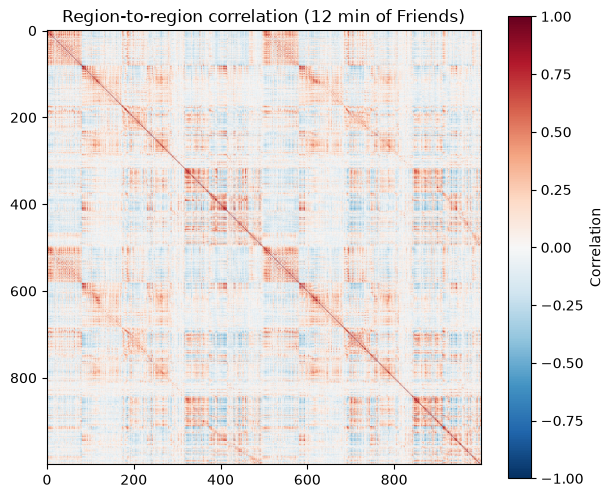

In [4]:
import numpy as np

r = np.corrcoef(data[:, 0], data[:, 500])[0, 1]
print('Correlation between region 1 and 501:', round(r, 2))

# correlation between every pair of regions
corr = np.corrcoef(data.T)
plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.title('Region-to-region correlation (12 min of Friends)')
plt.show()